# POS vs NEG: Cohort Comparison Across All Metrics

Side-by-side comparison of **POS** (reactivated after NI) vs **NEG** (never reactivated, NI ≥ 90 days).

**Base rate:** ~14.2% reactivation (140,130 POS / 846,296 NEG).

This notebook does one job: for every metric, show the cohort gap and label whether the pattern is **clear**, **weak**, **inverse**, or **leaky**.


In [1]:
from pathlib import Path
from IPython.display import display

# Cursor/VS Code notebooks default to Agg — force inline so figures render
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = Path("/Users/lekhanigam/RM Feature Analysis/reactivation_analysis")

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

binary = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="1_Binary_Metrics")
nums = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="2_Numeric_Metrics")
by_stage = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="3_By_Stage_Before_NI")
by_tier = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="4_By_NI_Tier")
by_proj = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="5_By_Project")
by_src = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="6_By_Born_Source")
score = pd.read_excel(OUT / "feature_scorecard.xlsx")
reco = pd.read_excel(OUT / "model_metrics_to_use.xlsx")
overview = pd.read_excel(OUT / "cohort_overview.xlsx")



def twin_bars(labels, pos, neg, title, ylabel="%"):
    """Two panels — POS left, NEG right — same x-scale so gaps are obvious."""
    labels = list(labels)
    pos = list(pos)
    neg = list(neg)
    fig, (ax_pos, ax_neg) = plt.subplots(
        1, 2, figsize=(12, max(3.2, 0.38 * len(labels))), sharey=True
    )
    y = np.arange(len(labels))
    ax_pos.barh(y, pos, color="#2a6f4e")
    ax_neg.barh(y, neg, color="#8a8a8a")
    ax_pos.set_yticks(y)
    ax_pos.set_yticklabels(labels)
    ax_pos.invert_yaxis()
    xmax = max([*pos, *neg, 1]) * 1.12
    for ax, name in ((ax_pos, "POS (reactivated)"), (ax_neg, "NEG (never reactivated)")):
        ax.set_xlim(0, xmax)
        ax.set_xlabel(ylabel)
        ax.set_title(name)
    fig.suptitle(title, fontsize=12, y=1.01)
    plt.tight_layout()
    display(fig)
    plt.close(fig)

print("Cohorts")
display(overview)
print(f"Binary metrics: {len(binary)} | Numeric: {len(nums)}")
print("matplotlib backend:", matplotlib.get_backend())


Cohorts


,metric,value
0,POS (reactivated LeadIds),140130.00
1,NEG (never reactivated LeadIds),846296.00
2,Total labeled LeadIds,986426.00
3,Reactivation rate %,14.21
4,Cross-project customers (unique MLIDs),153962.00
5,Cross-project NI leads (later positive elsewhere),247811.00
6,Cross-project with project-fit NI (budget/loca...,28876.00
7,% of cross-project NI leads with project-fit r...,11.70


Binary metrics: 13 | Numeric: 11
matplotlib backend: module://matplotlib_inline.backend_inline


## Pattern labels (rules used below)

| Label | Rule |
|-------|------|
| **Clear POS↑** | Gap ≥ +5 pp (POS higher) — useful separator |
| **Clear NEG↑ / inverse** | Gap ≤ −5 pp (NEG higher) — real gap, wrong direction to chase as “good” |
| **Weak / unclear** | |gap| < 5 pp, or both cohorts near-universal (~same high %) |
| **Leaky** | Strong gap but contaminated by outcome (e.g. oscillator = 2+ NI after reactivation) |
| **Control** | Large rate spread by project/source — include as features, not “signals” to chase |

Numeric: clear if |median gap| is large relative to scale (e.g. days_since_last_call −60d), weak if medians equal/near.


In [2]:
# ponytail: hard thresholds for pattern labels; upgrade = statistical tests / lift CI if needed
CLEAR_PP = 5.0

# Known special cases from prior analysis
LEAKY = {"2+ NI events (oscillator)"}
INVERSE_KNOWN = {
    "Any WhatsApp after NI",  # automation noise
    "Any website session before NI",
    "Viewed price / price sheet",
}

def label_binary(row):
    m = row["metric"]
    d = float(row["diff_pp"])
    pos, neg = float(row["POS_%"]), float(row["NEG_%"])
    if m in LEAKY:
        return "Leaky"
    if m in INVERSE_KNOWN or d <= -CLEAR_PP:
        return "Clear NEG↑ / inverse"
    if abs(d) < CLEAR_PP:
        # near-universal both sides → unclear even if tiny gap
        if min(pos, neg) >= 90:
            return "Weak / unclear (near-universal)"
        return "Weak / unclear"
    return "Clear POS↑"

cmp = binary.copy()
cmp["pattern"] = cmp.apply(label_binary, axis=1)
cmp = cmp.sort_values("diff_pp", ascending=False)

view = cmp[["category", "metric", "POS_%", "NEG_%", "diff_pp", "pattern"]].rename(
    columns={"POS_%": "POS %", "NEG_%": "NEG %", "diff_pp": "gap (pp)"}
)
display(view)

print("\nCounts by pattern:")
print(cmp["pattern"].value_counts().to_string())


,category,metric,POS %,NEG %,gap (pp),pattern
4,stage,2+ NI events (oscillator),98.64,0.17,98.47,Leaky
0,call,Any call after NI (≤90d),25.40,5.02,20.38,Clear POS↑
1,call,Inbound call after NI,16.79,1.63,15.16,Clear POS↑
2,call,≥5 calls before NI,43.94,33.78,10.16,Clear POS↑
8,website,Any website session after NI,5.98,0.25,5.72,Clear POS↑
11,whatsapp,User WhatsApp inbound after NI,10.90,6.07,4.83,Weak / unclear
5,stage,Pre Site Visit before NI,7.47,3.74,3.73,Weak / unclear
6,stage,Post Site Visit before NI,4.22,1.90,2.33,Weak / unclear
7,stage,NI reason = Personal Call,13.59,11.69,1.90,Weak / unclear
3,call,Any call before NI,95.50,94.05,1.45,Weak / unclear (near-universal)



Counts by pattern:
pattern
Clear POS↑                         4
Weak / unclear                     4
Clear NEG↑ / inverse               3
Leaky                              1
Weak / unclear (near-universal)    1


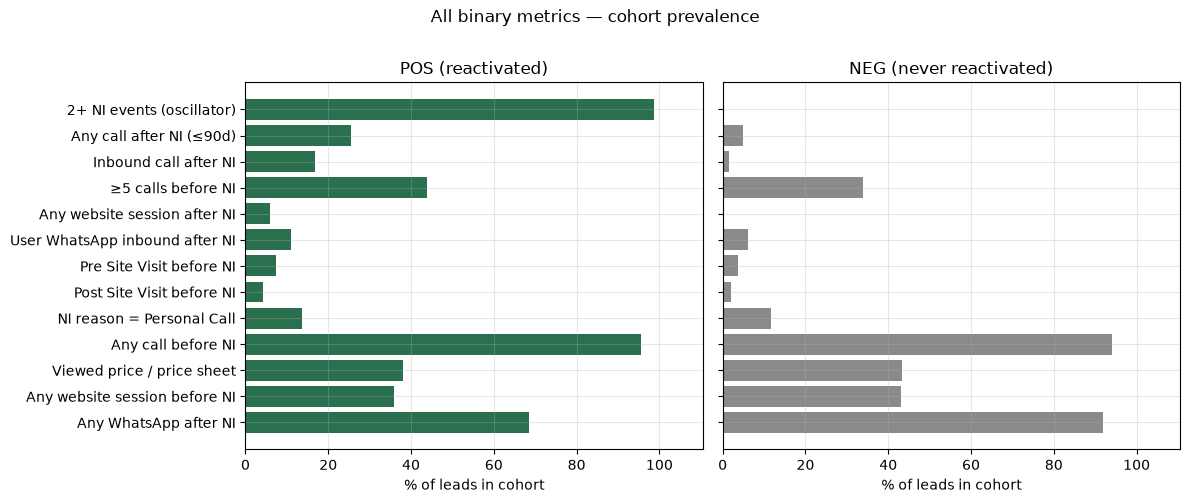

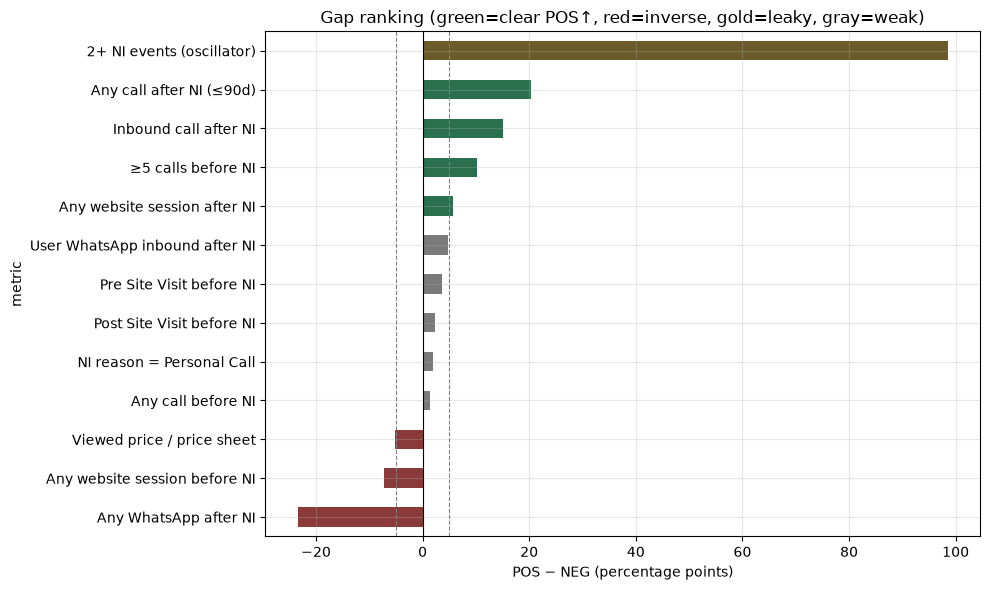

In [3]:
# Twin panels: every binary metric — POS % vs NEG % (same scale)
show = cmp.sort_values("diff_pp", ascending=False)
twin_bars(
    show["metric"],
    show["POS_%"],
    show["NEG_%"],
    title="All binary metrics — cohort prevalence",
    ylabel="% of leads in cohort",
)

# Gap chart (POS − NEG pp) for ranking
plot = cmp.sort_values("diff_pp")
fig, ax = plt.subplots(figsize=(10, 6))
colors = []
for ptn in plot["pattern"]:
    if ptn == "Clear POS↑":
        colors.append("#2a6f4e")
    elif ptn.startswith("Clear NEG"):
        colors.append("#8b3a3a")
    elif ptn == "Leaky":
        colors.append("#6b5b2a")
    else:
        colors.append("#7a7a7a")
plot.plot.barh(x="metric", y="diff_pp", ax=ax, color=colors, legend=False)
ax.axvline(0, color="black", lw=0.8)
ax.axvline(CLEAR_PP, color="gray", ls="--", lw=0.8)
ax.axvline(-CLEAR_PP, color="gray", ls="--", lw=0.8)
ax.set_xlabel("POS − NEG (percentage points)")
ax.set_title("Gap ranking (green=clear POS↑, red=inverse, gold=leaky, gray=weak)")
plt.tight_layout()
display(fig)
plt.close(fig)


## 1. Clear patterns (visible)

These separate POS from NEG with a gap ≥ 5 pp (or a large median gap).


In [4]:
clear = cmp[cmp["pattern"] == "Clear POS↑"].copy()
print(f"Clear POS↑ binary metrics: {len(clear)}\n")
for _, r in clear.iterrows():
    print(f"  • [{r['category']}] {r['metric']}: POS {r['POS_%']:.1f}% vs NEG {r['NEG_%']:.1f}% ({r['diff_pp']:+.1f} pp)")

# Numeric clear reads
print("\nNumeric clear reads:")
num_notes = [
    ("Days since last call", "POS median 30d vs NEG 90d (−60d) — POS contacted much more recently"),
    ("Calls after NI / inbound", "both medians 0, but POS mean higher & far fewer zeros (74.6% vs 95% zero post-calls)"),
    ("NI event count", "POS median 2 vs NEG 1 — but tied to oscillator leak; do not use raw"),
]
for name, note in num_notes:
    print(f"  • {name}: {note}")

display(clear[["category", "metric", "POS_%", "NEG_%", "diff_pp"]])


Clear POS↑ binary metrics: 4

  • [call] Any call after NI (≤90d): POS 25.4% vs NEG 5.0% (+20.4 pp)
  • [call] Inbound call after NI: POS 16.8% vs NEG 1.6% (+15.2 pp)
  • [call] ≥5 calls before NI: POS 43.9% vs NEG 33.8% (+10.2 pp)
  • [website] Any website session after NI: POS 6.0% vs NEG 0.2% (+5.7 pp)

Numeric clear reads:
  • Days since last call: POS median 30d vs NEG 90d (−60d) — POS contacted much more recently
  • Calls after NI / inbound: both medians 0, but POS mean higher & far fewer zeros (74.6% vs 95% zero post-calls)
  • NI event count: POS median 2 vs NEG 1 — but tied to oscillator leak; do not use raw


,category,metric,POS_%,NEG_%,diff_pp
0,call,Any call after NI (≤90d),25.40,5.02,20.38
1,call,Inbound call after NI,16.79,1.63,15.16
2,call,≥5 calls before NI,43.94,33.78,10.16
8,website,Any website session after NI,5.98,0.25,5.72


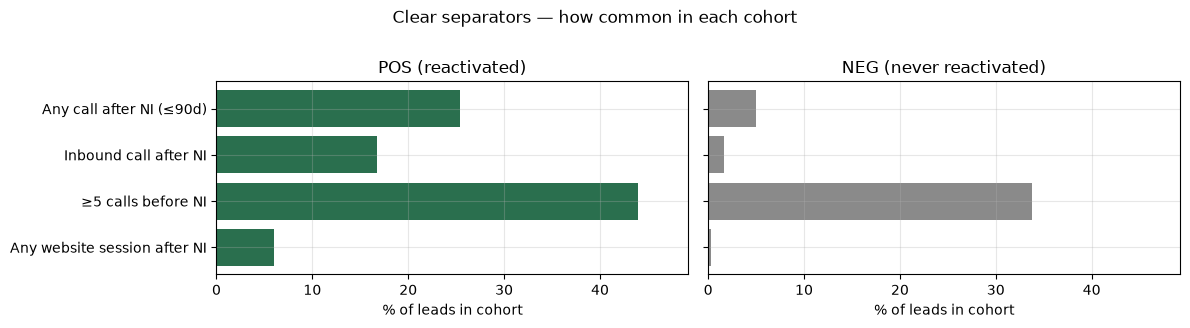

In [5]:
# Twin panels: clear separators only
if len(clear):
    twin_bars(
        clear["metric"],
        clear["POS_%"],
        clear["NEG_%"],
        title="Clear separators — how common in each cohort",
        ylabel="% of leads in cohort",
    )


## 2. Patterns that are NOT clear (or misleading)

Weak gaps, near-universal rates, inverse signals, and leaky metrics.


In [6]:
not_clear = cmp[cmp["pattern"] != "Clear POS↑"].copy()
display(
    not_clear[["category", "metric", "POS_%", "NEG_%", "diff_pp", "pattern"]].rename(
        columns={"POS_%": "POS %", "NEG_%": "NEG %", "diff_pp": "gap (pp)"}
    )
)

print("\nHow to read each bucket:")
print("  Weak / unclear — gap too small to rely on alone (e.g. any call before NI ~95% both).")
print("  Clear NEG↑ / inverse — real difference, but NEG is higher; do not chase as positive signal.")
print("  Leaky — looks strongest, but oscillator largely reflects post-reactivation NI repeats.")


,category,metric,POS %,NEG %,gap (pp),pattern
4,stage,2+ NI events (oscillator),98.64,0.17,98.47,Leaky
11,whatsapp,User WhatsApp inbound after NI,10.90,6.07,4.83,Weak / unclear
5,stage,Pre Site Visit before NI,7.47,3.74,3.73,Weak / unclear
6,stage,Post Site Visit before NI,4.22,1.90,2.33,Weak / unclear
7,stage,NI reason = Personal Call,13.59,11.69,1.90,Weak / unclear
3,call,Any call before NI,95.50,94.05,1.45,Weak / unclear (near-universal)
9,website,Viewed price / price sheet,38.16,43.36,-5.20,Clear NEG↑ / inverse
10,website,Any website session before NI,35.88,43.19,-7.31,Clear NEG↑ / inverse
12,whatsapp,Any WhatsApp after NI,68.59,91.98,-23.40,Clear NEG↑ / inverse



How to read each bucket:
  Weak / unclear — gap too small to rely on alone (e.g. any call before NI ~95% both).
  Clear NEG↑ / inverse — real difference, but NEG is higher; do not chase as positive signal.
  Leaky — looks strongest, but oscillator largely reflects post-reactivation NI repeats.


## 3. Full numeric comparison


In [7]:
nums_v = nums.copy()

def label_numeric(row):
    m = row["metric"]
    dm = row["diff_median"]
    if pd.isna(dm):
        return "POS-only / N/A"
    if "oscillator" in m.lower() or m == "NI event count":
        return "Leaky / careful"
    if abs(dm) >= 5:
        return "Clear median gap"
    # zero-rate gaps for sparse post-NI counts
    pz, nz = row.get("POS_pct_zero"), row.get("NEG_pct_zero")
    if pd.notna(pz) and pd.notna(nz) and abs(pz - nz) >= 10 and ("after NI" in m or "inbound" in m.lower()):
        return "Clear via % zero (sparse)"
    return "Weak / unclear"

nums_v["pattern"] = nums_v.apply(label_numeric, axis=1)
display(
    nums_v[
        [
            "category",
            "metric",
            "POS_median",
            "NEG_median",
            "POS_mean",
            "NEG_mean",
            "diff_median",
            "POS_pct_zero",
            "NEG_pct_zero",
            "pattern",
        ]
    ]
)


,category,metric,POS_median,NEG_median,POS_mean,NEG_mean,diff_median,POS_pct_zero,NEG_pct_zero,pattern
0,call,Calls before NI,4,3.0,5.40,4.31,1.0,4.5,6.0,Weak / unclear
1,call,Calls after NI,0,0.0,0.33,0.07,0.0,74.6,95.0,Clear via % zero (sparse)
2,call,Inbound calls after NI,0,0.0,0.19,0.02,0.0,83.2,98.4,Clear via % zero (sparse)
3,call,Days since last call,30,90.0,46.34,94.52,-60.0,33.2,5.9,Clear median gap
4,website,Website sessions before NI,0,0.0,0.39,0.45,0.0,64.1,56.8,Weak / unclear
5,website,Website sessions after NI,0,0.0,0.06,0.00,0.0,94.0,99.7,Weak / unclear
6,whatsapp,WhatsApp msgs before NI,4,4.0,8.56,7.36,0.0,13.9,8.5,Weak / unclear
7,whatsapp,WhatsApp msgs after NI,4,14.0,11.05,20.04,-10.0,31.4,8.0,Clear median gap
8,whatsapp,WA inbound count after NI,0,0.0,0.25,0.14,0.0,89.1,93.9,Weak / unclear
9,stage,NI event count,2,1.0,2.40,1.00,1.0,0.0,0.0,Leaky / careful


### POS vs NEG — numeric twin panels

Left = POS, right = NEG. Same axis scale.


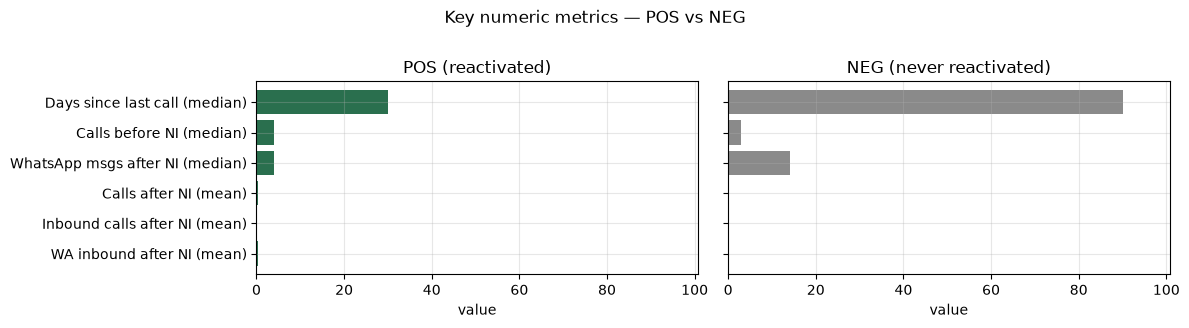

In [8]:
# Twin panels: key numeric medians (exclude POS-only / leaky NI count)
num_plot = nums_v[
    ~nums_v["metric"].isin(["Days NI → reactivation (POS only)", "NI event count"])
].copy()
# Prefer medians that differ; also show means for sparse post-NI counts
rows = [
    ("Days since last call (median)", "Days since last call", "POS_median", "NEG_median"),
    ("Calls before NI (median)", "Calls before NI", "POS_median", "NEG_median"),
    ("WhatsApp msgs after NI (median)", "WhatsApp msgs after NI", "POS_median", "NEG_median"),
    ("Calls after NI (mean)", "Calls after NI", "POS_mean", "NEG_mean"),
    ("Inbound calls after NI (mean)", "Inbound calls after NI", "POS_mean", "NEG_mean"),
    ("WA inbound after NI (mean)", "WA inbound count after NI", "POS_mean", "NEG_mean"),
]
labels, pos_v, neg_v = [], [], []
for lab, metric, pc, nc in rows:
    r = nums_v.loc[nums_v["metric"] == metric]
    if r.empty:
        continue
    labels.append(lab)
    pos_v.append(float(r.iloc[0][pc]))
    neg_v.append(float(r.iloc[0][nc]))

twin_bars(
    labels,
    pos_v,
    neg_v,
    title="Key numeric metrics — POS vs NEG",
    ylabel="value",
)


## 4. Segment rates (controls + structure)

Reactivation rate by stage, NI tier, project, source — clear spread = useful controls.


In [9]:
def rate_table(df, key, min_leads=500):
    t = df.copy()
    t = t[t["leads"] >= min_leads].sort_values("reactivation_rate_pct", ascending=False)
    spread = t["reactivation_rate_pct"].max() - t["reactivation_rate_pct"].min()
    print(f"{key}: rate spread {spread:.1f} pp (min n={min_leads})")
    print(f"  Clear structural pattern: {'YES' if spread >= 5 else 'NO / weak'}")
    return t

print("=== Stage before NI ===")
display(rate_table(by_stage, "stage_before_ni", min_leads=100))

print("=== NI reason tier ===")
display(rate_table(by_tier, "ni_reason_tier", min_leads=100))

print("=== Project ===")
display(rate_table(by_proj, "project_name", min_leads=100))

print("=== Born source (top by rate, n≥1000) ===")
src = by_src[by_src["leads"] >= 1000].sort_values("reactivation_rate_pct", ascending=False)
spread = src["reactivation_rate_pct"].max() - src["reactivation_rate_pct"].min()
print(f"born_source: rate spread {spread:.1f} pp among sources with n≥1000")
print(f"  Clear structural pattern: {'YES' if spread >= 5 else 'NO / weak'}")
display(src.drop(columns=["POS_pct", "NEG_pct"], errors="ignore").head(30))


=== Stage before NI ===
stage_before_ni: rate spread 33.4 pp (min n=100)
  Clear structural pattern: YES


,stage_before_ni,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,Flat Blocked,706,321,385,45.47,54.53,45.47,45.47,54.53
1,Post Site Visit,21408,5657,15751,26.42,73.58,26.42,26.42,73.58
2,Pre Site Visit,31667,6947,24720,21.94,78.06,21.94,21.94,78.06
3,Lead Initiated,317665,52901,264764,16.65,83.35,16.65,16.65,83.35
4,New Lead,614560,74183,540377,12.07,87.93,12.07,12.07,87.93


=== NI reason tier ===
ni_reason_tier: rate spread 11.8 pp (min n=100)
  Clear structural pattern: YES


,ni_reason_tier,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,SOFT,42339,8680,33659,20.50,79.50,20.50,20.50,79.50
1,MEDIUM,833189,121455,711734,14.58,85.42,14.58,14.58,85.42
2,HARD,5725,800,4925,13.97,86.03,13.97,13.97,86.03
3,SYSTEM,105173,9195,95978,8.74,91.26,8.74,8.74,91.26


=== Project ===
project_name: rate spread 36.9 pp (min n=100)
  Clear structural pattern: YES


,project_name,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,Legacy,13509,5996,7513,44.39,55.61,44.39,44.39,55.61
1,Loft,292271,48796,243475,16.70,83.30,16.70,16.70,83.30
2,Broadway,162106,23791,138315,14.68,85.32,14.68,14.68,85.32
3,Spectra,150719,21864,128855,14.51,85.49,14.51,14.51,85.49
4,Landmark,182235,22087,160148,12.12,87.88,12.12,12.12,87.88
5,Springs,126947,13186,113761,10.39,89.61,10.39,10.39,89.61
6,Spire,58639,4410,54229,7.52,92.48,7.52,7.52,92.48


=== Born source (top by rate, n≥1000) ===
born_source: rate spread 23.9 pp among sources with n≥1000
  Clear structural pattern: YES


,born_source,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct
0,Self Generated Lead,1461,415,1046,28.41,71.59,28.41
1,Lead Referral,1926,528,1398,27.41,72.59,27.41
2,magic-bricks-vl,1422,362,1060,25.46,74.54,25.46
3,Pre-launch Web,10966,2695,8271,24.58,75.42,24.58
4,Executive Referral,15857,3641,12216,22.96,77.04,22.96
5,Customer Referral,1895,384,1511,20.26,79.74,20.26
6,Whatsapp,69353,13811,55542,19.91,80.09,19.91
7,Walk In,5867,1147,4720,19.55,80.45,19.55
8,housing.com,28980,5579,23401,19.25,80.75,19.25
9,Channel Partner,73808,13957,59851,18.91,81.09,18.91


### POS vs NEG - where each cohort lives

Share of each cohort by stage and NI tier (composition, not reactivation rate).


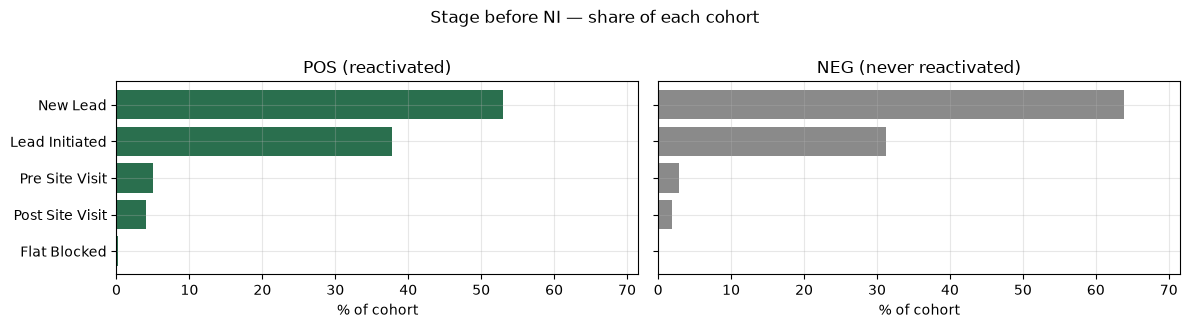

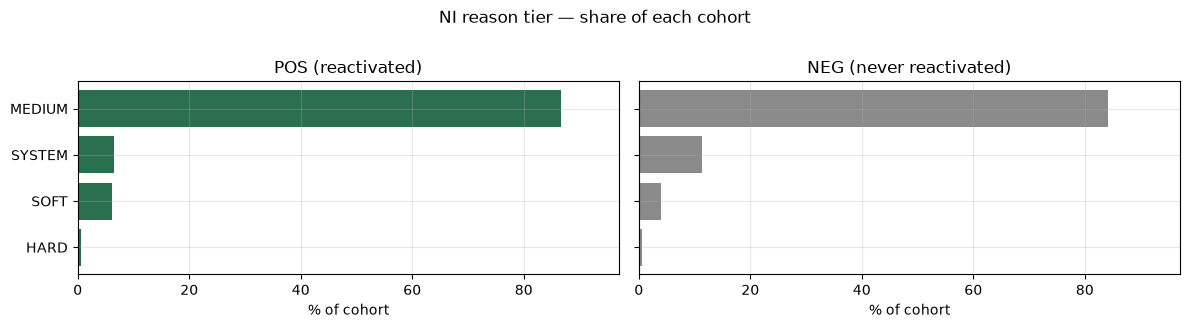

In [10]:
# Twin panels: where each cohort sits (share of cohort, not reactivation rate)
# Stage composition
stage_order = by_stage.sort_values("leads", ascending=False)
pos_share = 100 * stage_order["POS"] / stage_order["POS"].sum()
neg_share = 100 * stage_order["NEG"] / stage_order["NEG"].sum()
twin_bars(
    stage_order["stage_before_ni"],
    pos_share,
    neg_share,
    title="Stage before NI — share of each cohort",
    ylabel="% of cohort",
)

# NI tier composition
tier_order = by_tier.sort_values("leads", ascending=False)
pos_share = 100 * tier_order["POS"] / tier_order["POS"].sum()
neg_share = 100 * tier_order["NEG"] / tier_order["NEG"].sum()
twin_bars(
    tier_order["ni_reason_tier"],
    pos_share,
    neg_share,
    title="NI reason tier — share of each cohort",
    ylabel="% of cohort",
)


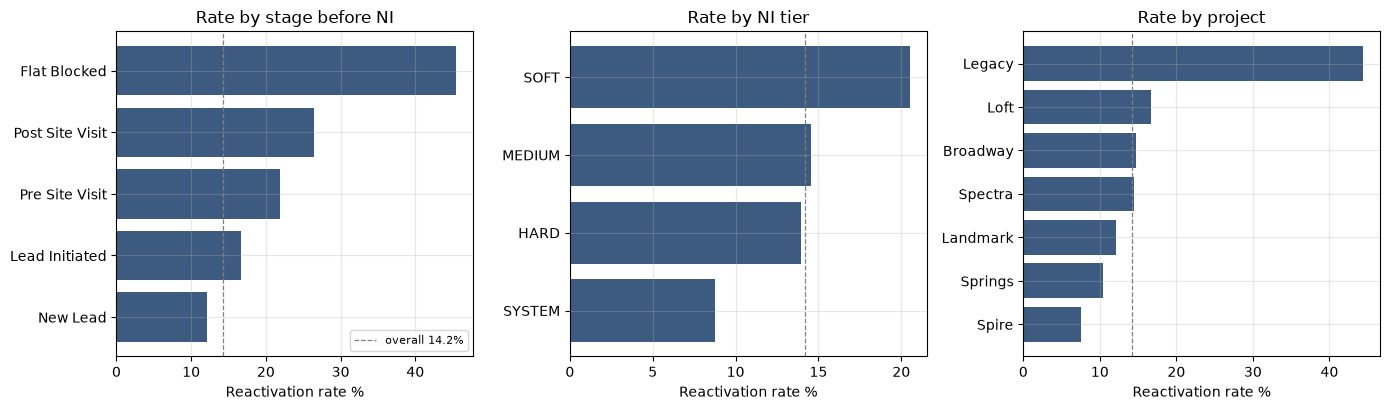

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, df, key, title in [
    (axes[0], by_stage.sort_values("reactivation_rate_pct"), "stage_before_ni", "Rate by stage before NI"),
    (axes[1], by_tier.sort_values("reactivation_rate_pct"), "ni_reason_tier", "Rate by NI tier"),
    (axes[2], by_proj.sort_values("reactivation_rate_pct"), "project_name", "Rate by project"),
]:
    ax.barh(df[key].astype(str), df["reactivation_rate_pct"], color="#3d5a80")
    ax.axvline(14.21, color="gray", ls="--", lw=0.9, label="overall 14.2%")
    ax.set_xlabel("Reactivation rate %")
    ax.set_title(title)
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)


## 5. Scorecard alignment (Keep / Modify / Remove)


In [12]:
sc = score.copy()
sc = sc.sort_values(["verdict", "diff_pp"], ascending=[True, False])
display(sc)

print("\nVerdict counts:")
print(sc["verdict"].value_counts().to_string())


,feature,category,coverage,diff_pp,verdict,note
7,bornsource,stage,1.000,63.66,Keep,source rate spread
12,days_since_last_call,call,0.944,60.00,Keep,median POS 30.0 vs NEG 90.0 (lower = more recent)
5,stage_before_ni,stage,1.000,33.40,Keep,prior stage rate spread
9,any_post_ni_call,call,1.000,20.38,Keep,Any call in post-NI window
10,any_post_ni_inbound,call,1.000,15.16,Keep,Inbound call in post-NI window
11,pre_ni_calls,call,1.000,10.16,Keep,more than equal to 5 calls before NI
4,ni_reason_tier,stage,1.000,6.53,Keep,SOFT 20.5% vs HARD 14.0%
16,any_post_web,website,0.483,5.72,Keep,Web session in post-NI window
21,any_post_wa_inbound,whatsapp,1.000,4.83,Keep,User WA inbound in post-NI window
0,had_pre_before_ni,stage,1.000,3.73,Keep,Pre Site Visit before NI



Verdict counts:
verdict
Keep      15
Modify     4
Remove     4


## 6. Verdict: what is clearly visible vs not

### Clearly visible
1. **Post-NI call engagement** - any post-NI call (+20 pp) and inbound (+15 pp) are the strongest clean separators.
2. **Call recency** - POS last-call median 30d vs NEG 90d.
3. **Funnel depth before NI** - Post SV ~26%, Pre SV ~22%, New Lead ~12%; had_pre / had_sv modest but real.
4. **NI reason tier** - SOFT ~20.5% vs SYSTEM ~8.7%.
5. **Post-NI web return** - rare (6% POS) but huge relative lift vs NEG (0.3%).
6. **Project / source** - large rate spreads; treat as controls.
7. **WA inbound after NI** - moderate clear gap (+4.8 pp, just under 5 pp hard cut but kept as signal).

### Not clear / do not treat as positive chase signals
1. **Any call before NI** - ~95% both cohorts; gap +1.5 pp is noise for ranking.
2. **Pickup ratio** - no median difference.
3. **Personal Call NI reason** - only +1.9 pp.
4. **Pre-NI web / viewed price** - NEG higher (inverse / coverage); not a reactivation “interest” signal as-is.
5. **Total WhatsApp after NI** - NEG much higher (−23 pp); automation noise - use **inbound only**.
6. **Oscillator (2+ NI)** - enormous gap but **leaky** (post-reactivation repeats).
7. **Website CTAs** - near-zero rates; remove.

### Borderline
- Pre-NI call intensity (≥5 calls): +10 pp - clear enough, medium priority.
- WA inbound: +4.8 pp - keep, smaller than calls.


In [13]:
# Compact decision table for all binary metrics
decision = cmp[["category", "metric", "POS_%", "NEG_%", "diff_pp", "pattern"]].copy()
decision["use"] = decision["pattern"].map(
    {
        "Clear POS↑": "Yes - separator",
        "Weak / unclear": "No / low weight",
        "Weak / unclear (near-universal)": "No",
        "Clear NEG↑ / inverse": "Investigate",
        "Leaky": "Modify only (prior-cycle)",
    }
)
# WA inbound sits at 4.83 — bump manually
mask_wa = decision["metric"].str.contains("WhatsApp inbound", case=False, na=False)
decision.loc[mask_wa, "pattern"] = "Clear POS↑ (borderline ≥4.5 pp)"
decision.loc[mask_wa, "use"] = "Yes - inbound only"

print("Final cohort comparison board")
display(decision.sort_values("diff_pp", ascending=False))

print("\nModel shortlist (from model_metrics_to_use.xlsx):")
display(reco)


Final cohort comparison board


,category,metric,POS_%,NEG_%,diff_pp,pattern,use
4,stage,2+ NI events (oscillator),98.64,0.17,98.47,Leaky,Modify only (prior-cycle)
0,call,Any call after NI (≤90d),25.40,5.02,20.38,Clear POS↑,Yes - separator
1,call,Inbound call after NI,16.79,1.63,15.16,Clear POS↑,Yes - separator
2,call,≥5 calls before NI,43.94,33.78,10.16,Clear POS↑,Yes - separator
8,website,Any website session after NI,5.98,0.25,5.72,Clear POS↑,Yes - separator
11,whatsapp,User WhatsApp inbound after NI,10.90,6.07,4.83,Clear POS↑ (borderline ≥4.5 pp),Yes - inbound only
5,stage,Pre Site Visit before NI,7.47,3.74,3.73,Weak / unclear,No / low weight
6,stage,Post Site Visit before NI,4.22,1.90,2.33,Weak / unclear,No / low weight
7,stage,NI reason = Personal Call,13.59,11.69,1.90,Weak / unclear,No / low weight
3,call,Any call before NI,95.50,94.05,1.45,Weak / unclear (near-universal),No



Model shortlist (from model_metrics_to_use.xlsx):


,priority,metric,why,use_in_model
0,HIGH,any_post_ni_inbound / post_ni_inbound,"POS 23,534 / 140,130 (16.8%) vs NEG 13,834 / 8...",Yes - post-NI window
1,HIGH,any_post_ni_call / post_ni_calls,"POS 35,596 / 140,130 (25.4%) vs NEG 42,524 / 8...",Yes
2,HIGH,days_since_last_call,POS median 30d vs NEG 90d - recency of contact.,Yes (capped at W)
3,HIGH,stage_before_ni + had_pre/had_sv before NI,Deeper funnel before NI → higher return rate.,Yes - available at NI time
4,HIGH,ni_reason_tier (SOFT vs HARD/SYSTEM),SOFT ~20.5% vs HARD ~14% vs SYSTEM ~8.7%.,Yes - at NI time
5,HIGH,project_name + born_source,Large rate spread; needed as features/controls.,Yes
6,HIGH,any_post_web,"POS 8,377 / 140,130 (6.0%) vs NEG 2,156 / 846,...",Yes when web coverage exists
7,HIGH,any_post_wa_inbound,"POS 15,273 / 140,130 (10.9%) vs NEG 51,357 / 8...",Yes - inbound only
8,MEDIUM,pre_ni_calls (≥5),+10 pp; intensity before NI.,Yes
9,MEDIUM,cross_project / project-fit NI flag,~154K customers NI on A then positive on B; 29...,Separate play / feature for multi-project


## Takeaway

**Visible:** post-NI engagement (especially inbound call), call recency, stage depth, NI tier, project/source, and rare post-NI web return.

**Not visible / misleading:** pre-NI “was contacted” flags, total WA volume, pre-NI web/price views, pickup ratio, and raw oscillator.

Use the clear separators for scoring; keep project/source as controls; drop or rewrite the rest.
